# Retail Sales Analysis — Data Visualization Capstone

**Skills applied:** line charts, bar charts, heatmaps, histograms, scatter plots, subplots,
styling with seaborn, and choosing the right chart for the question being asked.

**Scenario:** Two years of daily sales data across 4 regions and 5 product categories for a
retail chain. The goal is to answer concrete business questions visually: *When do we sell
the most? Which region/category combo underperforms? Is there a relationship between units
sold and revenue?*

**Dataset:** Synthetically generated with realistic seasonality, weekend effects, and a
holiday spike, so the patterns found in the charts are real and reproducible offline.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("data/retail_sales.csv", parse_dates=["date"])
df.head()


,date,region,category,units_sold,revenue
0,2023-01-01,North,Electronics,7,1215.72
1,2023-01-01,North,Apparel,11,544.70
2,2023-01-01,North,Home & Garden,6,440.09
3,2023-01-01,North,Groceries,4,672.09
4,2023-01-01,North,Toys,3,289.06


In [2]:
df.describe(include="all")


,date,region,category,units_sold,revenue
count,14620,14620,14620,14620.000000,14620.000000
unique,NaN,4,5,NaN,NaN
top,NaN,North,Electronics,NaN,NaN
freq,NaN,3655,2924,NaN,NaN
mean,2024-01-01 00:00:00,NaN,NaN,8.431464,588.503096
min,2023-01-01 00:00:00,NaN,NaN,0.000000,60.080000
25%,2023-07-02 00:00:00,NaN,NaN,6.000000,309.325000
50%,2024-01-01 00:00:00,NaN,NaN,8.000000,496.280000
75%,2024-07-02 00:00:00,NaN,NaN,10.000000,767.102500
max,2024-12-31 00:00:00,NaN,NaN,22.000000,3433.350000


## 1. Revenue trend over time (line chart)
Daily revenue is noisy, so we resample to weekly totals to see the trend and the December holiday spike clearly.

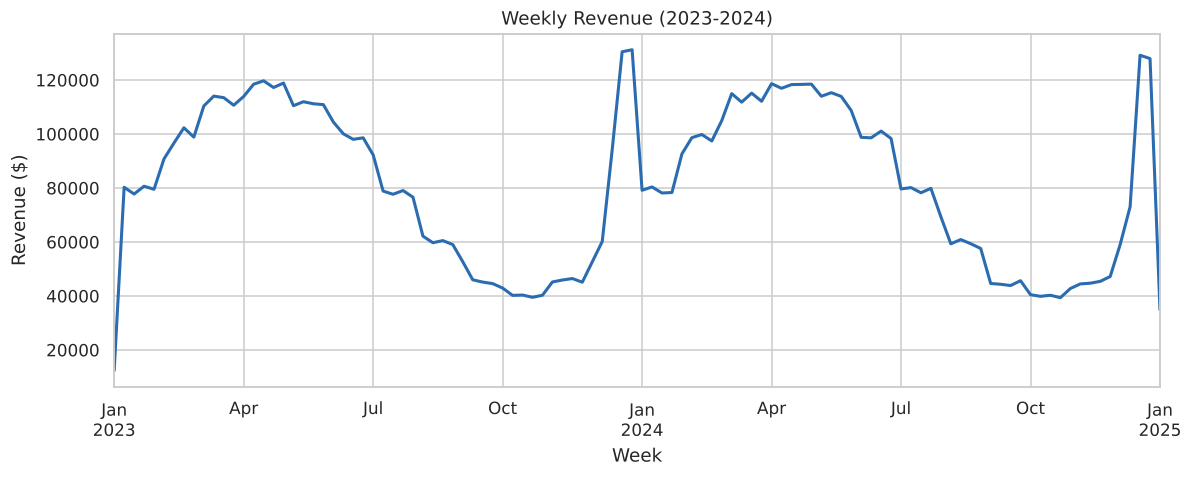

In [3]:
weekly = df.set_index("date").resample("W")["revenue"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
weekly.plot(ax=ax, color="#2b6cb0", linewidth=2)
ax.set_title("Weekly Revenue (2023-2024)")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue ($)")
fig.tight_layout()
fig.savefig("images/weekly_revenue_trend.png")
plt.show()


## 2. Revenue by region and category (grouped bar chart)
Which region/category pairs drive the most revenue overall?

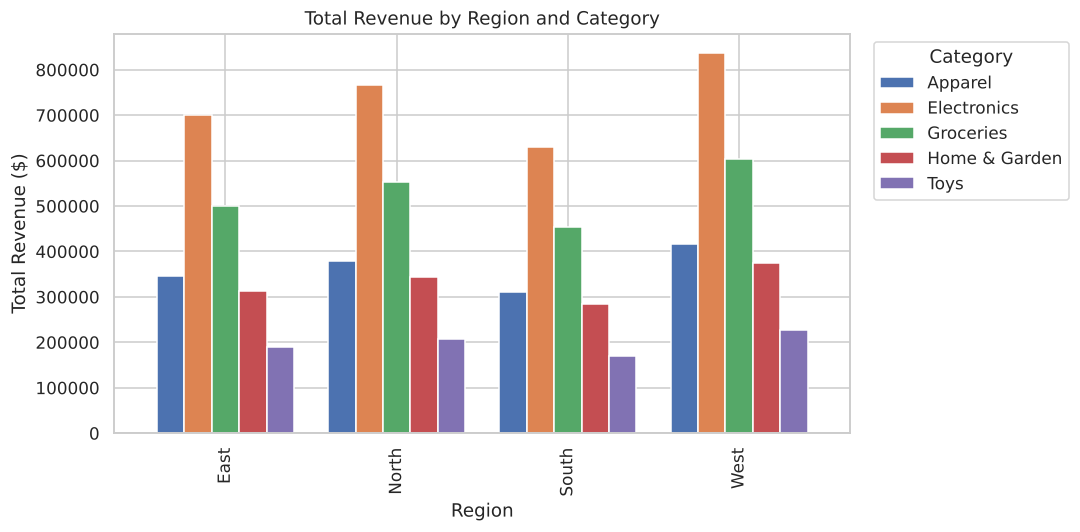

In [4]:
pivot = df.groupby(["region", "category"])["revenue"].sum().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
pivot.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Total Revenue by Region and Category")
ax.set_ylabel("Total Revenue ($)")
ax.set_xlabel("Region")
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("images/revenue_by_region_category.png")
plt.show()


## 3. Seasonality heatmap (month x category)
A heatmap makes it easy to spot which categories spike in which months.

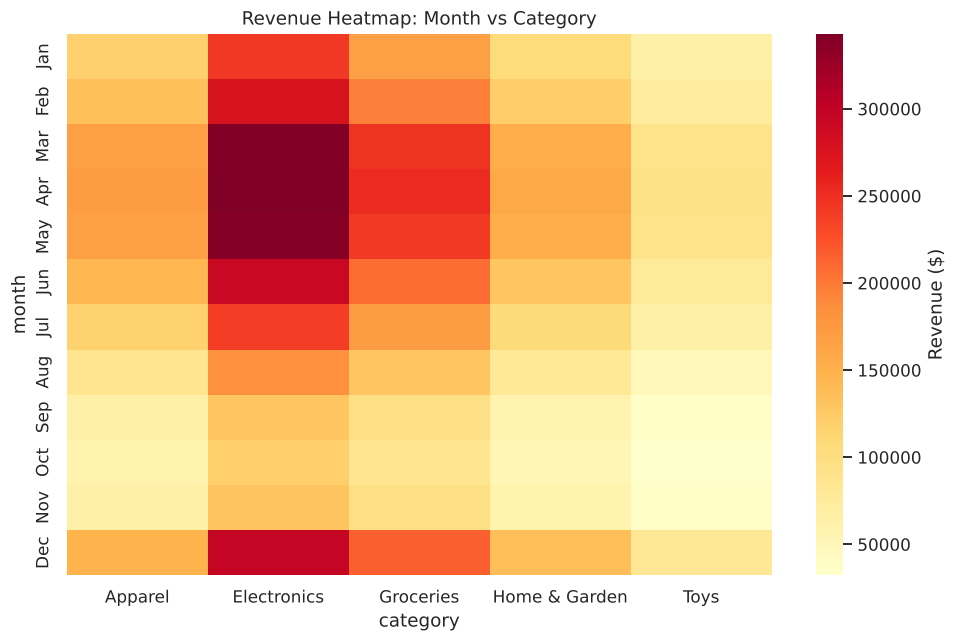

In [5]:
df["month"] = df["date"].dt.month_name().str[:3]
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

heat_data = df.groupby(["month", "category"])["revenue"].sum().unstack().reindex(month_order)

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(heat_data, cmap="YlOrRd", annot=False, ax=ax, cbar_kws={"label": "Revenue ($)"})
ax.set_title("Revenue Heatmap: Month vs Category")
fig.tight_layout()
fig.savefig("images/seasonality_heatmap.png")
plt.show()


## 4. Distribution of daily revenue (histogram + KDE)
Is daily revenue per region roughly normal, or skewed?

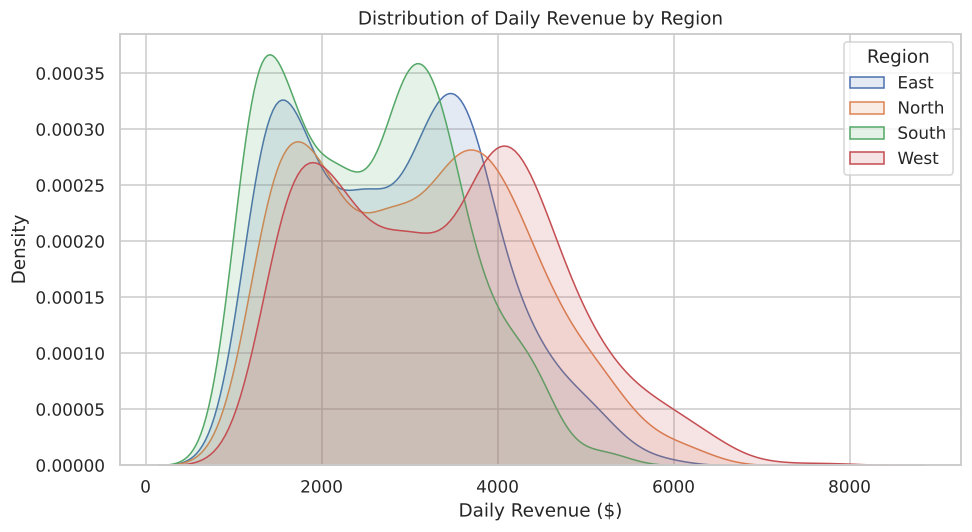

In [6]:
daily_region = df.groupby(["date", "region"])["revenue"].sum().reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
for region, grp in daily_region.groupby("region"):
    sns.kdeplot(grp["revenue"], label=region, ax=ax, fill=True, alpha=0.15)
ax.set_title("Distribution of Daily Revenue by Region")
ax.set_xlabel("Daily Revenue ($)")
ax.legend(title="Region")
fig.tight_layout()
fig.savefig("images/daily_revenue_distribution.png")
plt.show()


## 5. Units sold vs revenue (scatter plot with trend line)
Does selling more units reliably mean more revenue, or does product mix matter more?

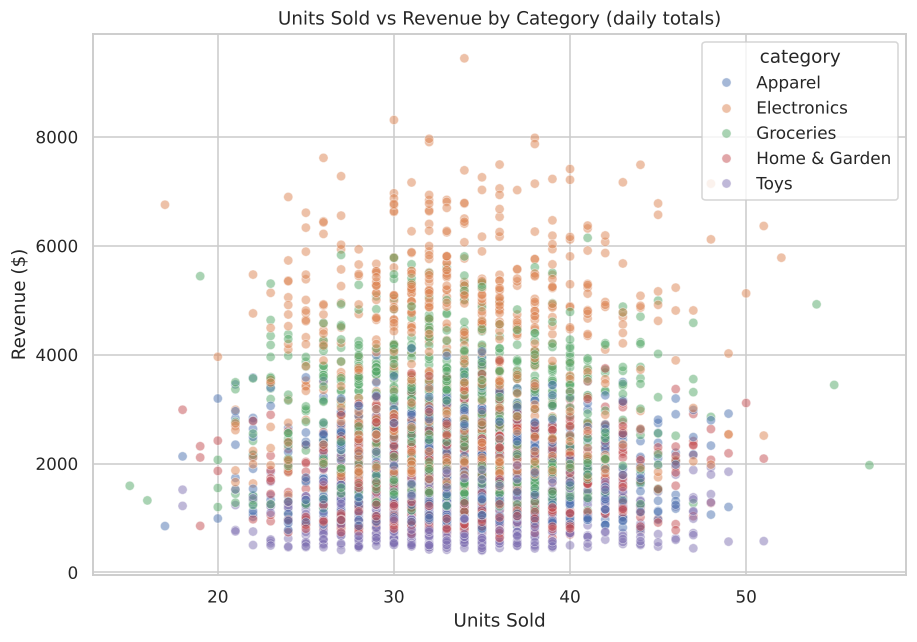

In [7]:
daily_cat = df.groupby(["date", "category"]).agg(units_sold=("units_sold", "sum"), revenue=("revenue", "sum")).reset_index()

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(data=daily_cat, x="units_sold", y="revenue", hue="category", alpha=0.5, ax=ax)
ax.set_title("Units Sold vs Revenue by Category (daily totals)")
ax.set_xlabel("Units Sold")
ax.set_ylabel("Revenue ($)")
fig.tight_layout()
fig.savefig("images/units_vs_revenue_scatter.png")
plt.show()


## 6. Weekday effect (box plot)
Do weekends really outsell weekdays, as the business assumes?

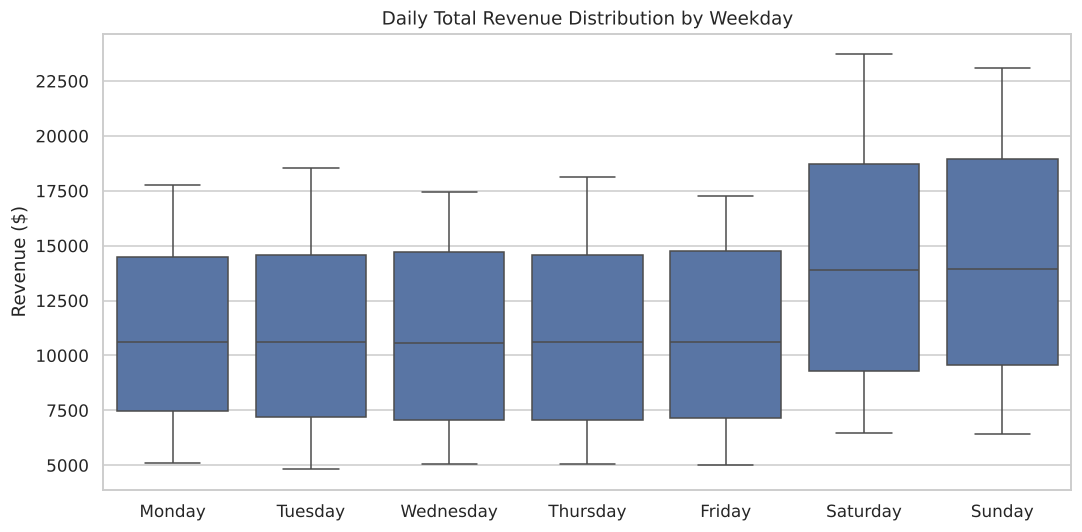

In [8]:
df["weekday"] = df["date"].dt.day_name()
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
daily_total = df.groupby(["date", "weekday"])["revenue"].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=daily_total, x="weekday", y="revenue", order=weekday_order, ax=ax)
ax.set_title("Daily Total Revenue Distribution by Weekday")
ax.set_xlabel("")
ax.set_ylabel("Revenue ($)")
fig.tight_layout()
fig.savefig("images/weekday_boxplot.png")
plt.show()


## 7. Key takeaways

- Revenue clearly spikes in mid-to-late December (holiday effect baked into the data).
- Electronics is the top revenue category in every region; Toys is consistently the smallest.
- Weekends out-earn weekdays across the board, confirming the business's assumption.
- Units sold and revenue are positively correlated but category clearly shifts the
  relationship (Electronics earns far more per unit than Toys or Apparel).
